# MAVLink Telemetry: Ground-Station Link Interruption Analysis

This notebook analyses one uploaded Mission Planner / ArduPilot .tlog file containing three stages:
1. Initial ground-station telemetry available
2. Ground-station telemetry interruption while SITL is intended to remain running
3. Ground-station telemetry restored
It extracts the same 12 telemetry variables, leaves unavailable values as NaN, detects timestamp gaps longer than a configurable threshold, and plots the recorded values against elapsed time. The detected gap is an inferred interval between the last packet received before the gap and the first packet received after it; the .tlog cannot show vehicle messages that the ground station did not receive. Therefore, this log alone cannot prove that SITL continued running during the interruption.

This is recorded-log analysis only. It does not independently verify physical GPS, Pixhawk, or radio hardware.

### 1. Import Libraries

In [2]:
%pip -q install pymavlink

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 42.1 MB/s eta 0:00:00


In [3]:
import math
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt
from pymavlink import mavutil

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

### 2. Upload the telemetry log

Upload the one .tlog file that contains the connected → interrupted → restored sequence. The notebook uses the first uploaded filename and does not check the file extension.

Gap detection setting: GAP_THRESHOLD_S sets the minimum time gap between two received packets to be flagged as a possible telemetry interruption.

In [4]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise ValueError("No file was uploaded.")

LOG_FILE = next(iter(uploaded.keys()))
print("Uploaded telemetry log:", LOG_FILE)

GAP_THRESHOLD_S = 0.1  # in seconds
print(f"Possible telemetry-gap threshold: {GAP_THRESHOLD_S:.1f} s")

Saving telemetry.tlog to telemetry.tlog
Uploaded telemetry log: telemetry.tlog
Possible telemetry-gap threshold: 0.1 s


### 3. Read the MAVLink messages

Each decoded MAVLink message is stored with its message type, log timestamp, and scalar fields. The elapsed time is measured from the first usable timestamp. Large gaps in this timeline can indicate that the ground station did not receive or record telemetry for a period.

In [5]:
def read_mavlink_log(path):
    connection = mavutil.mavlink_connection(
        path,
        robust_parsing=True,
    )

    rows = []
    first_timestamp = None

    while True:
        msg = connection.recv_match(blocking=False)

        if msg is None:
            break

        message_type = msg.get_type()

        if message_type == "BAD_DATA":
            continue

        timestamp = getattr(msg, "_timestamp", None)

        if timestamp is not None and timestamp > 0:
            if first_timestamp is None:
                first_timestamp = timestamp

            # Convert the timestamp to elapsed seconds.
            # pymavlink's log timestamp is in seconds.
            time_s = timestamp - first_timestamp
        else:
            time_s = float("nan")

        row = {
            "time_s": time_s,
            "message_type": message_type,
        }

        for field in msg.get_fieldnames():
            try:
                value = getattr(msg, field)

                if (
                    isinstance(value, (int, float, str, bool))
                    or value is None
                ):
                    row[field] = value

            except (AttributeError, TypeError, ValueError):
                pass

        rows.append(row)

    connection.close()

    return pd.DataFrame(rows)


messages = read_mavlink_log(LOG_FILE)

print("Telemetry log messages:", len(messages))
print(
    "Rows with valid elapsed time:",
    messages["time_s"].notna().sum(),
)

if messages["time_s"].notna().any():
    print(
        "Total recorded duration (s):",
        round(
            messages["time_s"].max()
            - messages["time_s"].min(),
            3,
        ),
    )

display(messages.head())

Telemetry log messages: 62731
Rows with valid elapsed time: 62731
Total recorded duration (s): 582.881


,time_s,message_type,type,autopilot,base_mode,custom_mode,system_status,mavlink_version,target_system,target_component,command,confirmation,param1,param2,param3,param4,param5,param6,param7,req_stream_id,req_message_rate,start_stop,param_id,param_value,param_type,param_count,param_index,result,progress,result_param2,severity,text,id,chunk_seq,time_boot_ms,arming_time_utc,takeoff_time_utc,flight_uuid,landing_time,omegaIx,omegaIy,omegaIz,accel_weight,renorm_val,error_rp,error_yaw,roll,pitch,yaw,altitude,lat,lng,rollspeed,pitchspeed,yawspeed,lon,alt,relative_alt,vx,vy,vz,hdg,airspeed,groundspeed,heading,throttle,climb,onboard_control_sensors_present,onboard_control_sensors_enabled,onboard_control_sensors_health,load,voltage_battery,current_battery,battery_remaining,drop_rate_comm,errors_comm,errors_count1,errors_count2,errors_count3,errors_count4,onboard_control_sensors_present_extended,onboard_control_sensors_enabled_extended,onboard_control_sensors_health_extended,Vcc,Vservo,flags,brkval,freemem,freemem32,nav_roll,nav_pitch,nav_bearing,target_bearing,wp_dist,alt_error,aspd_error,xtrack_error,seq,total,mission_state,mission_mode,time_usec,port,servo1_raw,servo2_raw,servo3_raw,servo4_raw,servo5_raw,servo6_raw,servo7_raw,servo8_raw,servo9_raw,servo10_raw,servo11_raw,servo12_raw,servo13_raw,servo14_raw,servo15_raw,servo16_raw,chancount,chan1_raw,chan2_raw,chan3_raw,chan4_raw,chan5_raw,chan6_raw,chan7_raw,chan8_raw,chan9_raw,chan10_raw,chan11_raw,chan12_raw,chan13_raw,chan14_raw,chan15_raw,chan16_raw,chan17_raw,chan18_raw,rssi,xacc,yacc,zacc,xgyro,ygyro,zgyro,xmag,ymag,zmag,temperature,press_abs,press_diff,temperature_press_diff,fix_type,eph,epv,vel,cog,satellites_visible,alt_ellipsoid,h_acc,v_acc,vel_acc,hdg_acc,time_unix_usec,spacing,terrain_height,current_height,pending,loaded,vibration_x,vibration_y,vibration_z,clipping_0,clipping_1,clipping_2,battery_function,current_consumed,energy_consumed,time_remaining,charge_state,mode,fault_bitmask,target_network,velocity_variance,pos_horiz_variance,pos_vert_variance,compass_variance,terrain_alt_variance,airspeed_variance,tc1,ts1,latitude,longitude,x,y,z,approach_x,approach_y,approach_z,capabilities,flight_sw_version,middleware_sw_version,os_sw_version,board_version,vendor_id,product_id,uid,direction,speed,speed_z,mission_type,frame,current,autocontinue,coordinate_frame,type_mask,lat_int,lon_int,afx,afy,afz,yaw_rate
0,0.000000,HEARTBEAT,6.0,8.0,0.0,0.0,0.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.029193,HEARTBEAT,2.0,3.0,89.0,0.0,1.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N

# 4. Inspect which message types are present

This is a quick inventory, not a validity check. Different logs may contain different message types, so some engineered fields may be unavailable.

In [6]:
display(messages["message_type"].value_counts().rename_axis("message_type").to_frame("count"))

,count
message_type,
AHRS2,2323
ATTITUDE,2323
VFR_HUD,2323
SIMSTATE,2322
ESC_TELEMETRY_1_TO_4,2310
SYS_STATUS,2077
RAW_IMU,2077
RC_CHANNELS,2077
SERVO_OUTPUT_RAW,2077


# 5. Feature engineering and Data Preprocessing

The output contains exactly these 10 requested fields:
1. Altitude (m)
2. Distance to waypoint (m)
3. Distance travelled (m)
4. Roll (deg)
5. Pitch (deg)
6. Yaw (deg)
7. Vertical speed (m/s)
9. Ground speed (m/s)
11. Latitude (degrees)
12. Longitude (degrees)

A field is recorded only when the relevant message provides it. Other rows stay NaN; there is no forward-filling or interpolation. Distance travelled is a cumulative estimate calculated from consecutive GPS positions, so it remains NaN when valid GPS positions are unavailable. If the time between GPS positions exceeds the gap threshold, the notebook does not add a straight-line distance across that interval, because the vehicle's path during missing telemetry is unknown.

This also preserves empty five-second bins as rows with NaN values. That is useful because otherwise missing time intervals may disappear from the plots.

In [12]:
import numpy as np

FEATURES = [
    "altitude_m",
    "distance_to_waypoint_m",
    "distance_travelled_m",
    "roll_deg",
    "pitch_deg",
    "yaw_deg",
    "vertical_speed_m_s",
    "ground_speed_m_s",
    "latitude_deg",
    "longitude_deg",
]

BIN_SIZE_S = 5


def distance_between_points(lat1, lon1, lat2, lon2):
    """Approximate surface distance in metres between two GPS coordinates."""

    earth_radius_m = 6_371_000

    lat1, lon1, lat2, lon2 = map(
        math.radians,
        [lat1, lon1, lat2, lon2],
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1)
        * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius_m * math.asin(
        math.sqrt(min(1, a))
    )


def engineer_features(messages, gap_threshold_s=GAP_THRESHOLD_S):
    rows = []
    distance_travelled = 0.0

    previous_position = None
    previous_position_time = None

    message_types = (
        set(messages["message_type"])
        if not messages.empty
        else set()
    )

    position_source = (
        "GLOBAL_POSITION_INT"
        if "GLOBAL_POSITION_INT" in message_types
        else "GPS_RAW_INT"
    )

    for _, msg in messages.iterrows():
        message_type = msg["message_type"]

        row = {
            name: float("nan")
            for name in FEATURES
        }

        row["time_s"] = msg.get("time_s", float("nan"))

        # Extract position and altitude.
        if message_type == "GLOBAL_POSITION_INT":

            if pd.notna(msg.get("alt")):
                row["altitude_m"] = msg["alt"] / 1000

            if (
                pd.notna(msg.get("lat"))
                and pd.notna(msg.get("lon"))
            ):
                lat = msg["lat"] / 1e7
                lon = msg["lon"] / 1e7

                row["latitude_deg"] = lat
                row["longitude_deg"] = lon

        elif (
            message_type == "GPS_RAW_INT"
            and position_source == "GPS_RAW_INT"
        ):

            if (
                pd.notna(msg.get("lat"))
                and pd.notna(msg.get("lon"))
            ):
                lat = msg["lat"] / 1e7
                lon = msg["lon"] / 1e7

                if not (lat == 0 and lon == 0):
                    row["latitude_deg"] = lat
                    row["longitude_deg"] = lon

        # Extract speed and vertical speed.
        elif message_type == "VFR_HUD":

            if pd.notna(msg.get("alt")):
                row["altitude_m"] = msg["alt"]

            if pd.notna(msg.get("climb")):
                row["vertical_speed_m_s"] = msg["climb"]

            if pd.notna(msg.get("groundspeed")):
                row["ground_speed_m_s"] = msg["groundspeed"]

        # Extract distance to the current waypoint.
        elif message_type == "NAV_CONTROLLER_OUTPUT":

            if pd.notna(msg.get("wp_dist")):
                row["distance_to_waypoint_m"] = msg["wp_dist"]

        # Convert attitude from radians to degrees.
        elif message_type == "ATTITUDE":

            for source, target in [
                ("roll", "roll_deg"),
                ("pitch", "pitch_deg"),
                ("yaw", "yaw_deg"),
            ]:
                if pd.notna(msg.get(source)):
                    row[target] = math.degrees(msg[source])

        # Calculate observed cumulative distance from GPS positions.
        lat = row["latitude_deg"]
        lon = row["longitude_deg"]
        current_time = row["time_s"]

        if pd.notna(lat) and pd.notna(lon):

            if (
                previous_position is not None
                and pd.notna(current_time)
                and pd.notna(previous_position_time)
                and current_time - previous_position_time
                > gap_threshold_s
            ):
                # Do not estimate the unknown path across a long gap.
                previous_position = None

            if previous_position is not None:
                distance_travelled += distance_between_points(
                    previous_position[0],
                    previous_position[1],
                    lat,
                    lon,
                )

            row["distance_travelled_m"] = distance_travelled

            previous_position = (lat, lon)
            previous_position_time = current_time

        rows.append(row)

    result = pd.DataFrame(
        rows,
        columns=["time_s"] + FEATURES,
    )

    return result


telemetry_data = engineer_features(messages)

print("Telemetry feature table:", telemetry_data.shape)
print("Number of retained features:", len(FEATURES))

display(telemetry_data.head())
valid_data = telemetry_data.dropna(
    subset=["time_s"]
).copy()

valid_data["time_bin_s"] = (
    np.floor(valid_data["time_s"] / BIN_SIZE_S)
    * BIN_SIZE_S
).astype(int)

median_data = (
    valid_data
    .groupby("time_bin_s")[FEATURES]
    .median()
)

if not valid_data.empty:
    all_bins = range(
        0,
        int(valid_data["time_bin_s"].max()) + BIN_SIZE_S,
        BIN_SIZE_S,
    )

    median_data = median_data.reindex(all_bins)

median_data.index.name = "time_bin_s"

median_data = (
    median_data
    .reset_index()
    .rename(columns={"time_bin_s": "time_s"})
)

print("Five-second median feature table:", median_data.shape)
display(median_data.head(10))

print("Descriptive statistics of five-second medians:")
display(median_data[FEATURES].describe().T)

Telemetry feature table: (62731, 11)
Number of retained features: 10


,time_s,altitude_m,distance_to_waypoint_m,distance_travelled_m,roll_deg,pitch_deg,yaw_deg,vertical_speed_m_s,ground_speed_m_s,latitude_deg,longitude_deg
0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.029193,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.108468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.110984,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.111392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Five-second median feature table: (117, 11)


,time_s,altitude_m,distance_to_waypoint_m,distance_travelled_m,roll_deg,pitch_deg,yaw_deg,vertical_speed_m_s,ground_speed_m_s,latitude_deg,longitude_deg
0,0,0.000000,0.0,0.0,0.006055,-0.003534,-19.802122,-0.014725,0.000221,0.000000,0.000000
1,5,292.044983,0.0,0.0,0.009515,-0.002156,-19.671818,0.015325,0.000579,-17.681631,74.582619
2,10,584.089966,0.0,0.0,0.017755,0.004509,-4.710159,0.007302,0.003126,-35.363262,149.165237
3,15,584.089983,0.0,0.0,0.029496,0.017922,-3.058652,0.002290,0.009790,-35.363262,149.165237
4,20,584.089983,0.0,0.0,0.047800,0.033285,-3.289326,0.002542,0.021135,-35.363262,149.165237
5,25,584.089983,0.0,0.0,0.062512,0.048478,-3.741332,0.002411,0.033083,-35.363262,149.165237
6,30,584.089983,0.0,0.0,0.074281,0.061345,-4.192130,0.000609,0.042705,-35.363262,149.165237
7,35,584.090000,0.0,0.0,0.082141,0.070075,-4.520033,0.000119,0.048326,-35.363262,149.165237
8,40,584.089966,0.0,0.0,0.090172,0.079414,-4.808494,-0.000238,0.024530,-35.363262,149.165237
9,45,584.089966,0.0,0.0,0.061115,0.050721,-5.003626,-0.000106,0.019224,-35.363262,149.165237


Descriptive statistics of five-second medians:


,count,mean,std,min,25%,50%,75%,max
altitude_m,117.0,593.414729,65.983806,0.000000,584.089983,584.099988,634.050000,634.099976
distance_to_waypoint_m,117.0,48.653846,106.686728,0.000000,0.000000,0.000000,5.000000,489.000000
distance_travelled_m,117.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
roll_deg,117.0,-1.487428,6.067103,-27.372192,-0.060342,0.061115,0.074281,0.308003
pitch_deg,117.0,-4.997735,10.479312,-29.340276,-0.033232,-0.021097,0.059956,1.238582
yaw_deg,117.0,37.894089,85.244293,-173.750334,-7.443916,-5.380424,130.069553,133.636503
vertical_speed_m_s,117.0,-0.006481,0.554108,-1.500921,-0.000249,0.000003,0.000609,2.501091
ground_speed_m_s,117.0,2.263045,4.039062,0.000221,0.023481,0.023910,0.291187,10.022876
latitude_deg,117.0,-34.909839,3.642595,-35.364768,-35.363262,-35.363262,-35.363262,0.000000
longitude_deg,117.0,147.252123,15.364708,0.000000,149.165043,149.165237,149.165237,149.165241


# 6. Missing values summary

In [33]:
missing_summary = pd.DataFrame({
    "field": FEATURES,
    "missing_count": [
        telemetry_data[field].isna().sum()
        for field in FEATURES
    ],
    "available_count": [
        telemetry_data[field].notna().sum()
        for field in FEATURES
    ],
})

print("Missing-value summary before aggregation:")
display(missing_summary)

Missing-value summary before aggregation:


,field,missing_count,available_count
0,altitude_m,58331,4400
1,distance_to_waypoint_m,60654,2077
2,distance_travelled_m,62731,0
3,roll_deg,60408,2323
4,pitch_deg,60408,2323
5,yaw_deg,60408,2323
6,vertical_speed_m_s,60408,2323
7,ground_speed_m_s,60408,2323
8,latitude_deg,58600,4131
9,longitude_deg,58600,4131


# 7. Detect gaps in the original message timestamps

In [13]:
# Detect gaps in the original message timestamps

GAP_THRESHOLD_S = 0.1

valid_times = (
    messages["time_s"]
    .dropna()
    .sort_values()
    .reset_index(drop=True)
)

time_differences = (
    valid_times.iloc[1:].to_numpy()
    - valid_times.iloc[:-1].to_numpy()
)

gap_rows = []

for position, duration in enumerate(time_differences):
    if duration > GAP_THRESHOLD_S:
        previous_time = float(valid_times.iloc[position])
        current_time = float(valid_times.iloc[position + 1])

        gap_rows.append({
            "gap_start_s": previous_time,
            "gap_end_s": current_time,
            "gap_duration_s": float(duration),
        })

gap_events = pd.DataFrame(
    gap_rows,
    columns=[
        "gap_start_s",
        "gap_end_s",
        "gap_duration_s",
    ],
)

# Create the intervals used by the plotting function.
gap_intervals = list(
    zip(
        gap_events["gap_start_s"],
        gap_events["gap_end_s"],
    )
)

if gap_events.empty:
    print(
        "No consecutive-message timestamp gaps exceeded "
        f"{GAP_THRESHOLD_S:g} seconds."
    )
else:
    print(f"Detected {len(gap_events)} possible timestamp gap(s):")
    display(gap_events)

if not telemetry_data["time_s"].notna().any():
    print(
        "WARNING: No usable timestamps were decoded. "
        "Time-based aggregation and gap detection may be unreliable."
    )

Detected 2679 possible timestamp gap(s):


,gap_start_s,gap_end_s,gap_duration_s
0,0.193009,0.301977,0.108968
1,0.301977,0.586481,0.284504
2,0.751609,0.862617,0.111008
3,0.932897,1.106836,0.173939
4,1.606745,1.726185,0.119440
...,...,...,...
2674,581.905392,582.026569,0.121177
2675,582.129945,582.380249,0.250304
2676,582.384397,582.525633,0.141236
2677,582.632785,582.741793,0.109008


# 8. Exploratory plots for all 10 fields

Each chart shows the recorded values against elapsed time for both files. Scatter plots are used because different MAVLink messages arrive at different times. Missing values remain missing; the notebook does not connect or invent values between message updates. Grey shaded regions indicate possible gaps longer than GAP_THRESHOLD_S.

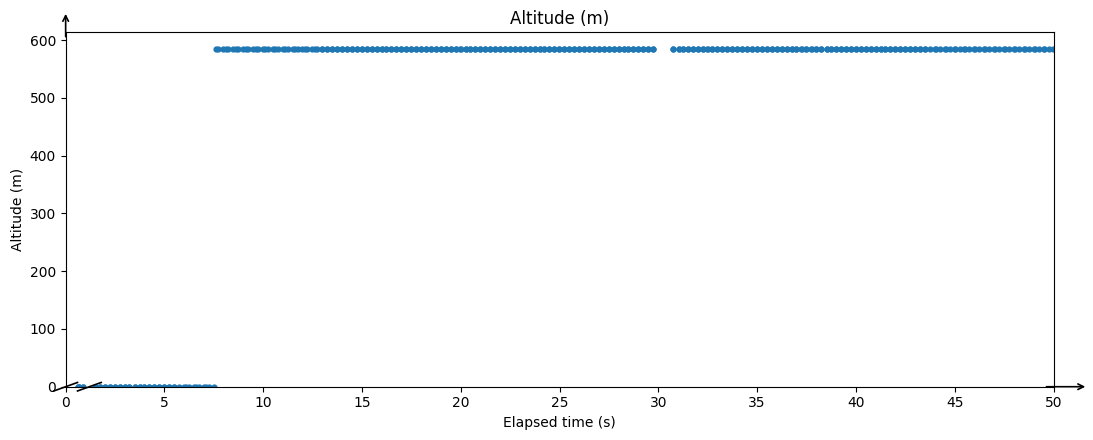

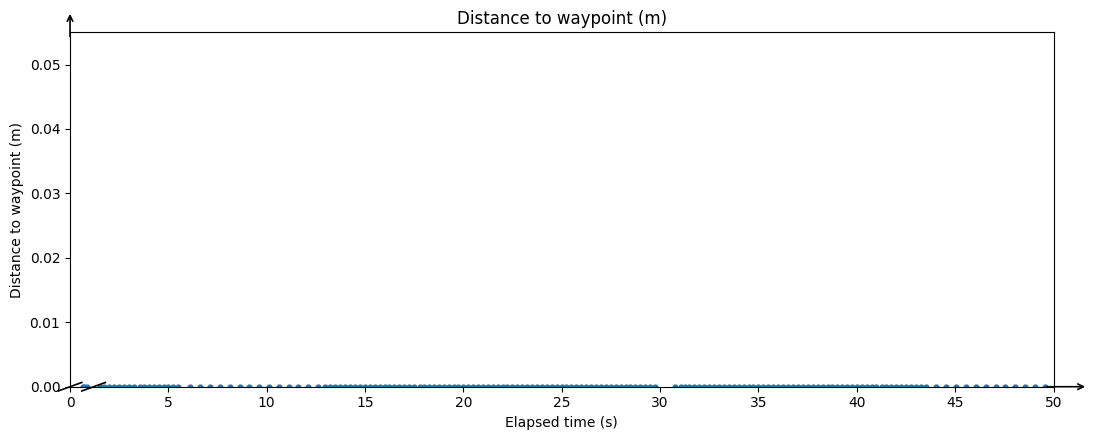

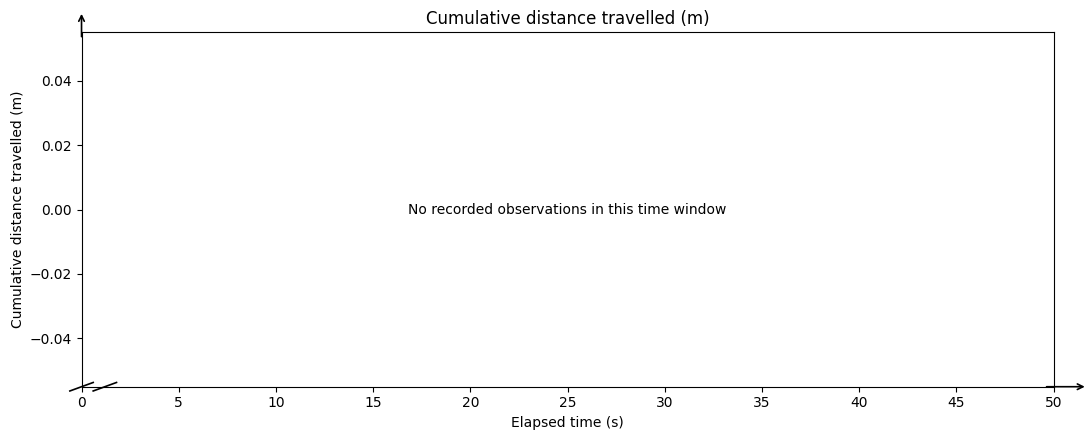

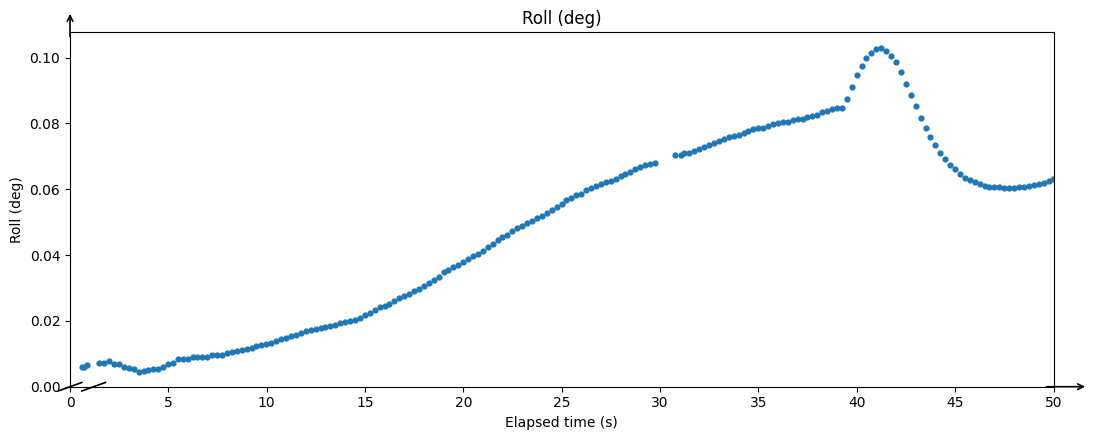

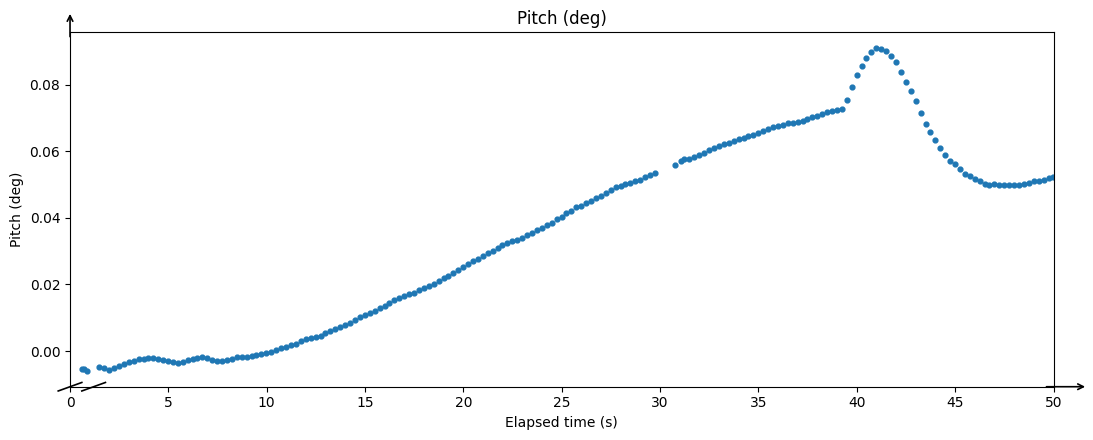

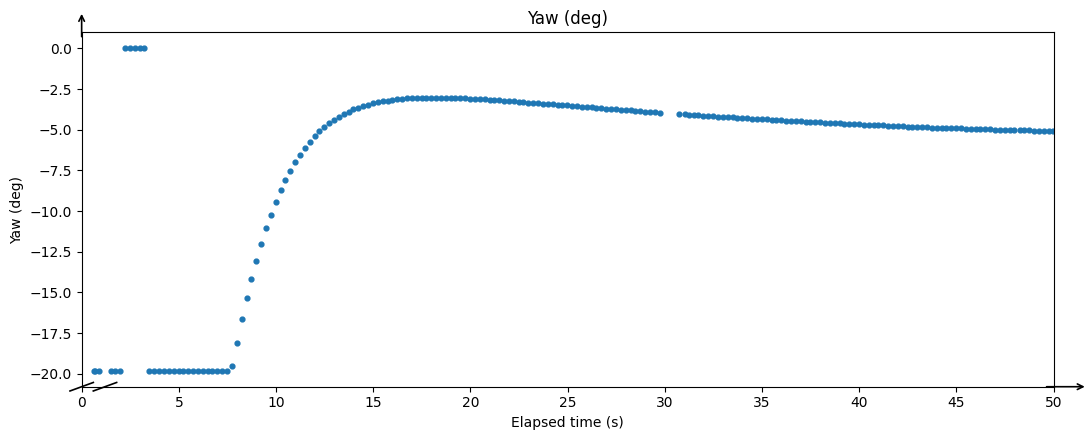

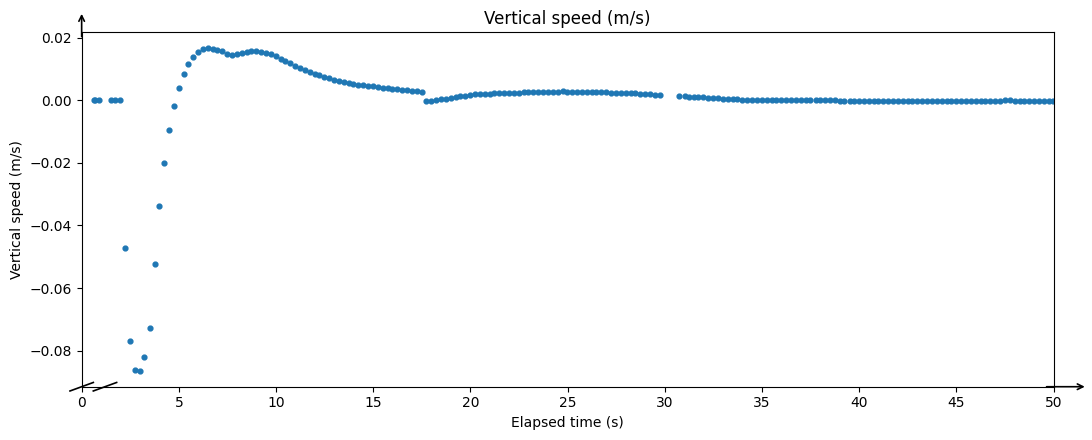

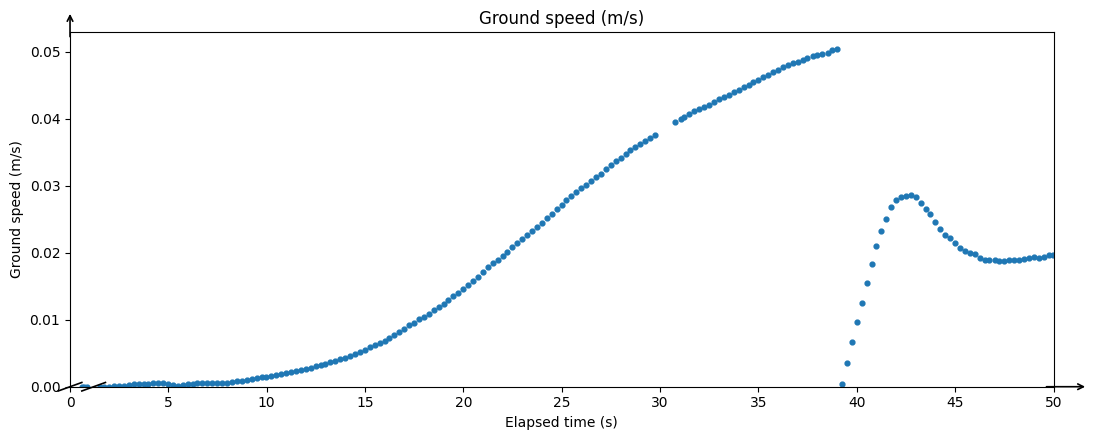

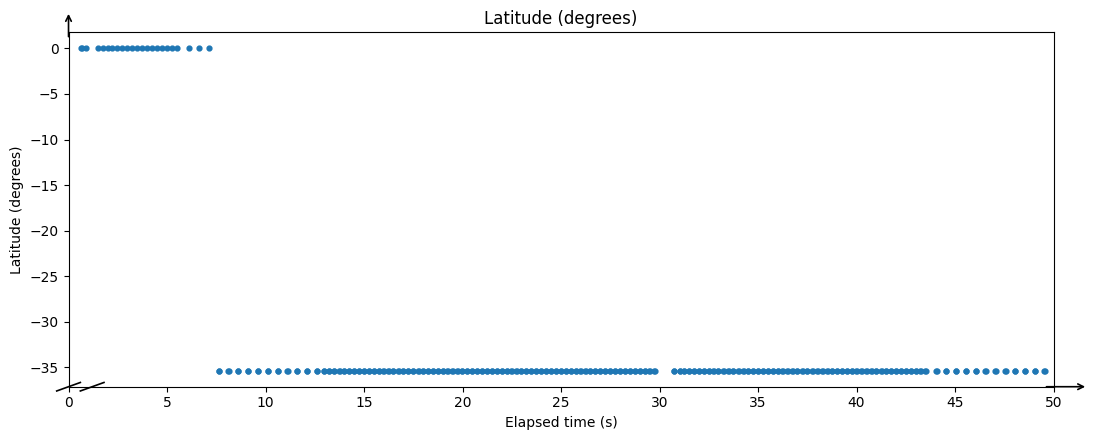

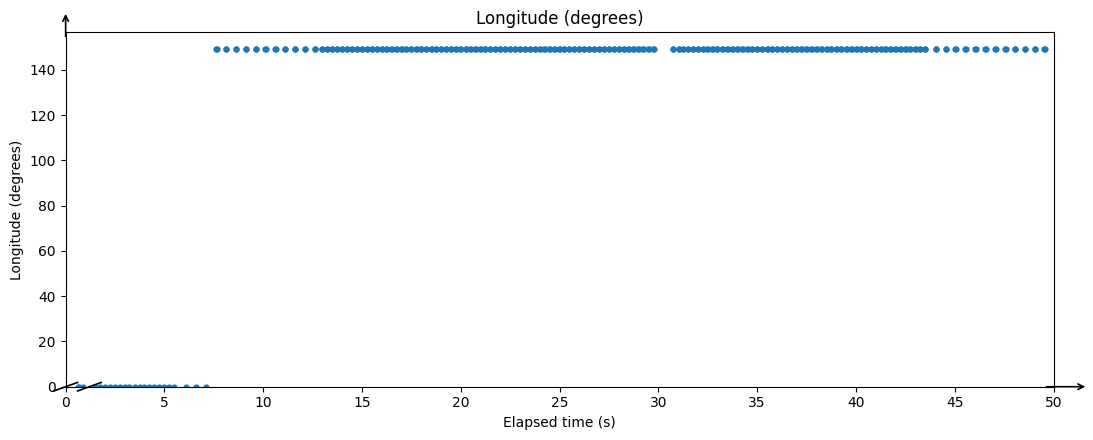

In [25]:

FIELD_LABELS = {
    "altitude_m": "Altitude (m)",
    "distance_to_waypoint_m": "Distance to waypoint (m)",
    "distance_travelled_m": "Cumulative distance travelled (m)",
    "roll_deg": "Roll (deg)",
    "pitch_deg": "Pitch (deg)",
    "yaw_deg": "Yaw (deg)",
    "vertical_speed_m_s": "Vertical speed (m/s)",
    "ground_speed_m_s": "Ground speed (m/s)",
    "latitude_deg": "Latitude (degrees)",
    "longitude_deg": "Longitude (degrees)",
}

PLOT_START_S = 0
PLOT_END_S = 50


def plot_field(field):
    fig, ax = plt.subplots(figsize=(11, 4.5))

    usable = telemetry_data[["time_s", field]].dropna()

    usable = usable[
        (usable["time_s"] >= PLOT_START_S)
        & (usable["time_s"] <= PLOT_END_S)
    ]

    if not usable.empty:
        ax.scatter(
            usable["time_s"],
            usable[field],
            s=12,
            label="Recorded observations",
        )

        y_min = usable[field].min()
        y_max = usable[field].max()

        if y_min >= 0:
            ax.set_ylim(bottom=0)
        elif y_min == y_max:
            ax.set_ylim(y_min - 1, y_max + 1)

    else:
        ax.text(
            0.5,
            0.5,
            "No recorded observations in this time window",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )

    ax.set_xlim(PLOT_START_S, PLOT_END_S)
    ax.set_xticks(
        range(PLOT_START_S, PLOT_END_S + 1, 5)
    )

    ax.set_title(FIELD_LABELS.get(field, field))
    ax.set_xlabel("Elapsed time (s)")
    ax.set_ylabel(FIELD_LABELS.get(field, field))

    # No grid, shading, or connecting lines.
    ax.grid(False)

    # Arrowhead at the end of the x-axis.
    ax.annotate(
        "",
        xy=(1.035, 0),
        xytext=(0.99, 0),
        xycoords="axes fraction",
        arrowprops=dict(arrowstyle="->", linewidth=1.2),
        annotation_clip=False,
    )

    # Arrowhead at the end of the y-axis.
    ax.annotate(
        "",
        xy=(0, 1.06),
        xytext=(0, 0.98),
        xycoords="axes fraction",
        arrowprops=dict(arrowstyle="->", linewidth=1.2),
        annotation_clip=False,
    )

    # Kink marks at the beginning of the displayed x-axis.
    ax.plot(
        [-0.012, 0.012],
        [-0.012, 0.012],
        transform=ax.transAxes,
        color="black",
        clip_on=False,
        linewidth=1.2,
    )

    ax.plot(
        [0.012, 0.036],
        [-0.012, 0.012],
        transform=ax.transAxes,
        color="black",
        clip_on=False,
        linewidth=1.2,
    )

    fig.tight_layout()
    plt.show()


for field in FEATURES:
    plot_field(field)


# 9. Save the engineered data and gap summary

The CSV files preserve missing values as empty CSV cells, which pandas reads back as NaN by default.

In [34]:
telemetry_data.to_csv("telemetry_features.csv", index=False)
missing_summary.to_csv("telemetry_missing_value_summary.csv", index=False)
gap_events.to_csv("possible_telemetry_gaps.csv", index=False)

print("Saved:")
print("- telemetry_features.csv")
print("- telemetry_missing_value_summary.csv")
print("- possible_telemetry_gaps.csv")

Saved:
- telemetry_features.csv
- telemetry_missing_value_summary.csv
- possible_telemetry_gaps.csv


In [35]:
files.download("telemetry_features.csv")
files.download("telemetry_missing_value_summary.csv")
files.download("possible_telemetry_gaps.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 10. Applying Extended Kalman Filter

In [36]:

import numpy as np
import pandas as pd

# EKF input: five-second median data ONLY
BIN_SIZE_S = 5

FEATURES = [
    "altitude_m",
    "distance_to_waypoint_m",
    "distance_travelled_m",
    "roll_deg",
    "pitch_deg",
    "yaw_deg",
    "vertical_speed_m_s",
    "ground_speed_m_s",
    "latitude_deg",
    "longitude_deg",
]

# Measurement-noise standard deviations.
# These are tunable assumptions, not measurements from the log.
MEASUREMENT_STD = {
    "altitude_m": 2.0,
    "distance_to_waypoint_m": 5.0,
    "distance_travelled_m": 5.0,
    "roll_deg": 5.0,
    "pitch_deg": 5.0,
    "yaw_deg": 10.0,
    "vertical_speed_m_s": 1.0,
    "ground_speed_m_s": 1.0,
    "latitude_deg": 0.00001,
    "longitude_deg": 0.00001,
}

# Process-noise standard deviations per five-second bin.
PROCESS_STD = {
    "altitude_m": 1.0,
    "distance_to_waypoint_m": 2.0,
    "distance_travelled_m": 2.0,
    "roll_deg": 3.0,
    "pitch_deg": 3.0,
    "yaw_deg": 5.0,
    "vertical_speed_m_s": 0.5,
    "ground_speed_m_s": 0.5,
    "latitude_deg": 0.000005,
    "longitude_deg": 0.000005,
}

# Confirm that the expected input columns exist.
required_columns = ["time_s"] + FEATURES
missing_columns = [
    column for column in required_columns
    if column not in median_data.columns
]

if missing_columns:
    raise ValueError(
        f"These required columns are missing from median_data: "
        f"{missing_columns}"
    )

# Work on a copy so median_data remains unchanged.
ekf_input = (
    median_data[required_columns]
    .copy()
    .sort_values("time_s")
    .reset_index(drop=True)
)

if ekf_input["time_s"].isna().any():
    raise ValueError("median_data contains missing time_s values.")

if ekf_input["time_s"].duplicated().any():
    raise ValueError("median_data contains duplicate time_s values.")

n_features = len(FEATURES)
feature_index = {
    feature: i for i, feature in enumerate(FEATURES)
}

measurement_variance = np.array([
    MEASUREMENT_STD[f] ** 2 for f in FEATURES
])

process_variance = np.array([
    PROCESS_STD[f] ** 2 for f in FEATURES
])

# Feature indices used by the state-transition model.
ALT = feature_index["altitude_m"]
TRAVELLED = feature_index["distance_travelled_m"]
VERTICAL_SPEED = feature_index["vertical_speed_m_s"]
GROUND_SPEED = feature_index["ground_speed_m_s"]
YAW = feature_index["yaw_deg"]
LAT = feature_index["latitude_deg"]
LON = feature_index["longitude_deg"]

EARTH_RADIUS_M = 6_371_000.0


def predict_state(x, dt, initialized):
    """
    Predict the state over dt seconds.

    A state is propagated only when its own initial value and
    the required supporting states have been observed.
    """
    x_pred = x.copy()

    # Altitude changes according to logged vertical speed.
    if initialized[ALT] and initialized[VERTICAL_SPEED]:
        x_pred[ALT] += x[VERTICAL_SPEED] * dt

    # Cumulative distance is propagated only if it was
    # initialized from an actual logged measurement.
    if initialized[TRAVELLED] and initialized[GROUND_SPEED]:
        x_pred[TRAVELLED] += max(x[GROUND_SPEED], 0.0) * dt

    # Approximate horizontal motion using speed and heading.
    # No latitude/longitude is invented before both coordinates
    # have been observed.
    if (
        initialized[LAT]
        and initialized[LON]
        and initialized[GROUND_SPEED]
        and initialized[YAW]
    ):
        speed = max(x[GROUND_SPEED], 0.0)
        heading_rad = np.deg2rad(x[YAW])
        latitude_rad = np.deg2rad(x[LAT])

        north_velocity = speed * np.cos(heading_rad)
        east_velocity = speed * np.sin(heading_rad)

        x_pred[LAT] += (
            north_velocity * dt / EARTH_RADIUS_M
        ) * (180.0 / np.pi)

        cos_latitude = max(abs(np.cos(latitude_rad)), 1e-6)

        x_pred[LON] += (
            east_velocity * dt
            / (EARTH_RADIUS_M * cos_latitude)
        ) * (180.0 / np.pi)

    # Other states use a persistence model between measurements.
    return x_pred


def numerical_jacobian(x, dt, initialized):
    """Approximate the transition-model Jacobian numerically."""
    F = np.zeros((n_features, n_features))

    for j in range(n_features):
        step = max(abs(x[j]) * 1e-6, 1e-6)

        x_plus = x.copy()
        x_minus = x.copy()

        x_plus[j] += step
        x_minus[j] -= step

        f_plus = predict_state(x_plus, dt, initialized)
        f_minus = predict_state(x_minus, dt, initialized)

        F[:, j] = (f_plus - f_minus) / (2.0 * step)

    return F


# Internal EKF state.
x = np.zeros(n_features, dtype=float)
P = np.zeros((n_features, n_features), dtype=float)
initialized = np.zeros(n_features, dtype=bool)

estimated_rows = []
empty_measurement_flags = []
timestamp_gap_flags = []

previous_time = None

for _, row in ekf_input.iterrows():
    current_time = float(row["time_s"])

    z = row[FEATURES].to_numpy(dtype=float)
    valid_measurement = np.isfinite(z)

    # Detect missing timestamp intervals separately from
    # bins that simply contain no measurements.
    if previous_time is None:
        dt = 0.0
        timestamp_gap = False
    else:
        dt = current_time - previous_time

        if dt < 0:
            raise ValueError("time_s must be in ascending order.")

        timestamp_gap = dt > BIN_SIZE_S + 1e-6

    # Prediction step: uses the previous EKF state, not raw messages.
    if previous_time is not None and dt > 0:
        F = numerical_jacobian(x, dt, initialized)
        x = predict_state(x, dt, initialized)

        Q = np.diag(process_variance * (dt / BIN_SIZE_S))
        Q[~initialized, :] = 0.0
        Q[:, ~initialized] = 0.0

        P = F @ P @ F.T + Q

    previously_initialized = initialized.copy()

    # Initialize a feature only when its median measurement exists.
    # No unavailable feature is initialized to zero.
    newly_initialized = valid_measurement & ~initialized

    for i in np.where(newly_initialized)[0]:
        x[i] = z[i]

        # Reset covariance links for this newly initialized state.
        P[i, :] = 0.0
        P[:, i] = 0.0
        P[i, i] = measurement_variance[i]

        initialized[i] = True

    # Measurement update for states that already had an estimate.
    update_indices = np.where(
        valid_measurement & previously_initialized
    )[0]

    if len(update_indices) > 0:
        H = np.zeros((len(update_indices), n_features))

        for measurement_row, state_index in enumerate(update_indices):
            H[measurement_row, state_index] = 1.0

        R = np.diag(measurement_variance[update_indices])
        z_update = z[update_indices]

        innovation = z_update - H @ x
        S = H @ P @ H.T + R
        K = P @ H.T @ np.linalg.pinv(S)

        x = x + K @ innovation

        # Joseph form helps maintain a numerically stable covariance.
        I = np.eye(n_features)
        P = (
            (I - K @ H) @ P @ (I - K @ H).T
            + K @ R @ K.T
        )

    # Report estimates only for initialized states.
    # Unavailable variables remain NaN.
    estimated_rows.append([
        x[i] if initialized[i] else np.nan
        for i in range(n_features)
    ])

    empty_measurement_flags.append(not valid_measurement.any())
    timestamp_gap_flags.append(timestamp_gap)

    previous_time = current_time


# Store estimates separately from the original median measurements.
ekf_estimates = pd.DataFrame(
    estimated_rows,
    columns=[f"{feature}_ekf" for feature in FEATURES],
    index=ekf_input.index,
)

median_ekf_data = pd.concat(
    [ekf_input, ekf_estimates],
    axis=1,
)

median_ekf_data["no_measurements_in_bin"] = (
    empty_measurement_flags
)

median_ekf_data["timestamp_gap"] = timestamp_gap_flags

print("EKF completed on median_data.")
print("Input rows:", len(ekf_input))
print("Output rows:", len(median_ekf_data))
display(median_ekf_data.head())

EKF completed on median_data.
Input rows: 117
Output rows: 117


,time_s,altitude_m,distance_to_waypoint_m,distance_travelled_m,roll_deg,pitch_deg,yaw_deg,vertical_speed_m_s,ground_speed_m_s,latitude_deg,longitude_deg,altitude_m_ekf,distance_to_waypoint_m_ekf,distance_travelled_m_ekf,roll_deg_ekf,pitch_deg_ekf,yaw_deg_ekf,vertical_speed_m_s_ekf,ground_speed_m_s_ekf,latitude_deg_ekf,longitude_deg_ekf,no_measurements_in_bin,timestamp_gap
0,0,0.000000,0.0,NaN,0.006055,-0.003534,-19.802122,-0.014725,0.000221,0.000000,0.000000,0.000000,0.000000,NaN,0.006055,-0.003534,-19.802122,-0.014725,2.213982e-04,0.000000,0.000000,False,False
1,5,292.044983,0.0,NaN,0.009515,-0.002156,-19.671818,0.015325,0.000579,-35.363262,149.165237,241.006799,0.000034,NaN,0.008049,-0.002740,4385.989781,28.356516,-1.242180e+06,-48.842310,93.381982,False,False
2,10,584.089966,0.0,NaN,0.017755,0.004509,-4.710159,0.007302,0.003126,-35.363262,149.165237,530.904533,-0.021912,NaN,0.012742,0.000765,3027.700612,35.296988,-8.567853e+05,-42.830645,118.270639,False,False
3,15,584.089983,0.0,NaN,0.029496,0.017922,-3.058652,0.002290,0.009790,-35.363262,149.165237,605.155335,-0.014232,NaN,0.020408,0.008616,1899.413890,17.390047,-5.471682e+05,-39.732256,130.938657,False,False
4,20,584.089983,0.0,NaN,0.047800,0.033285,-3.289326,0.002542,0.021135,-35.363262,149.165237,606.823298,-0.009304,NaN,0.032729,0.019713,1167.346654,5.379628,-3.394576e+05,-37.984658,138.184674,False,False


# 11. Plot the median measurements against EKF estimates

This plots each original five-second median alongside its EKF estimate.

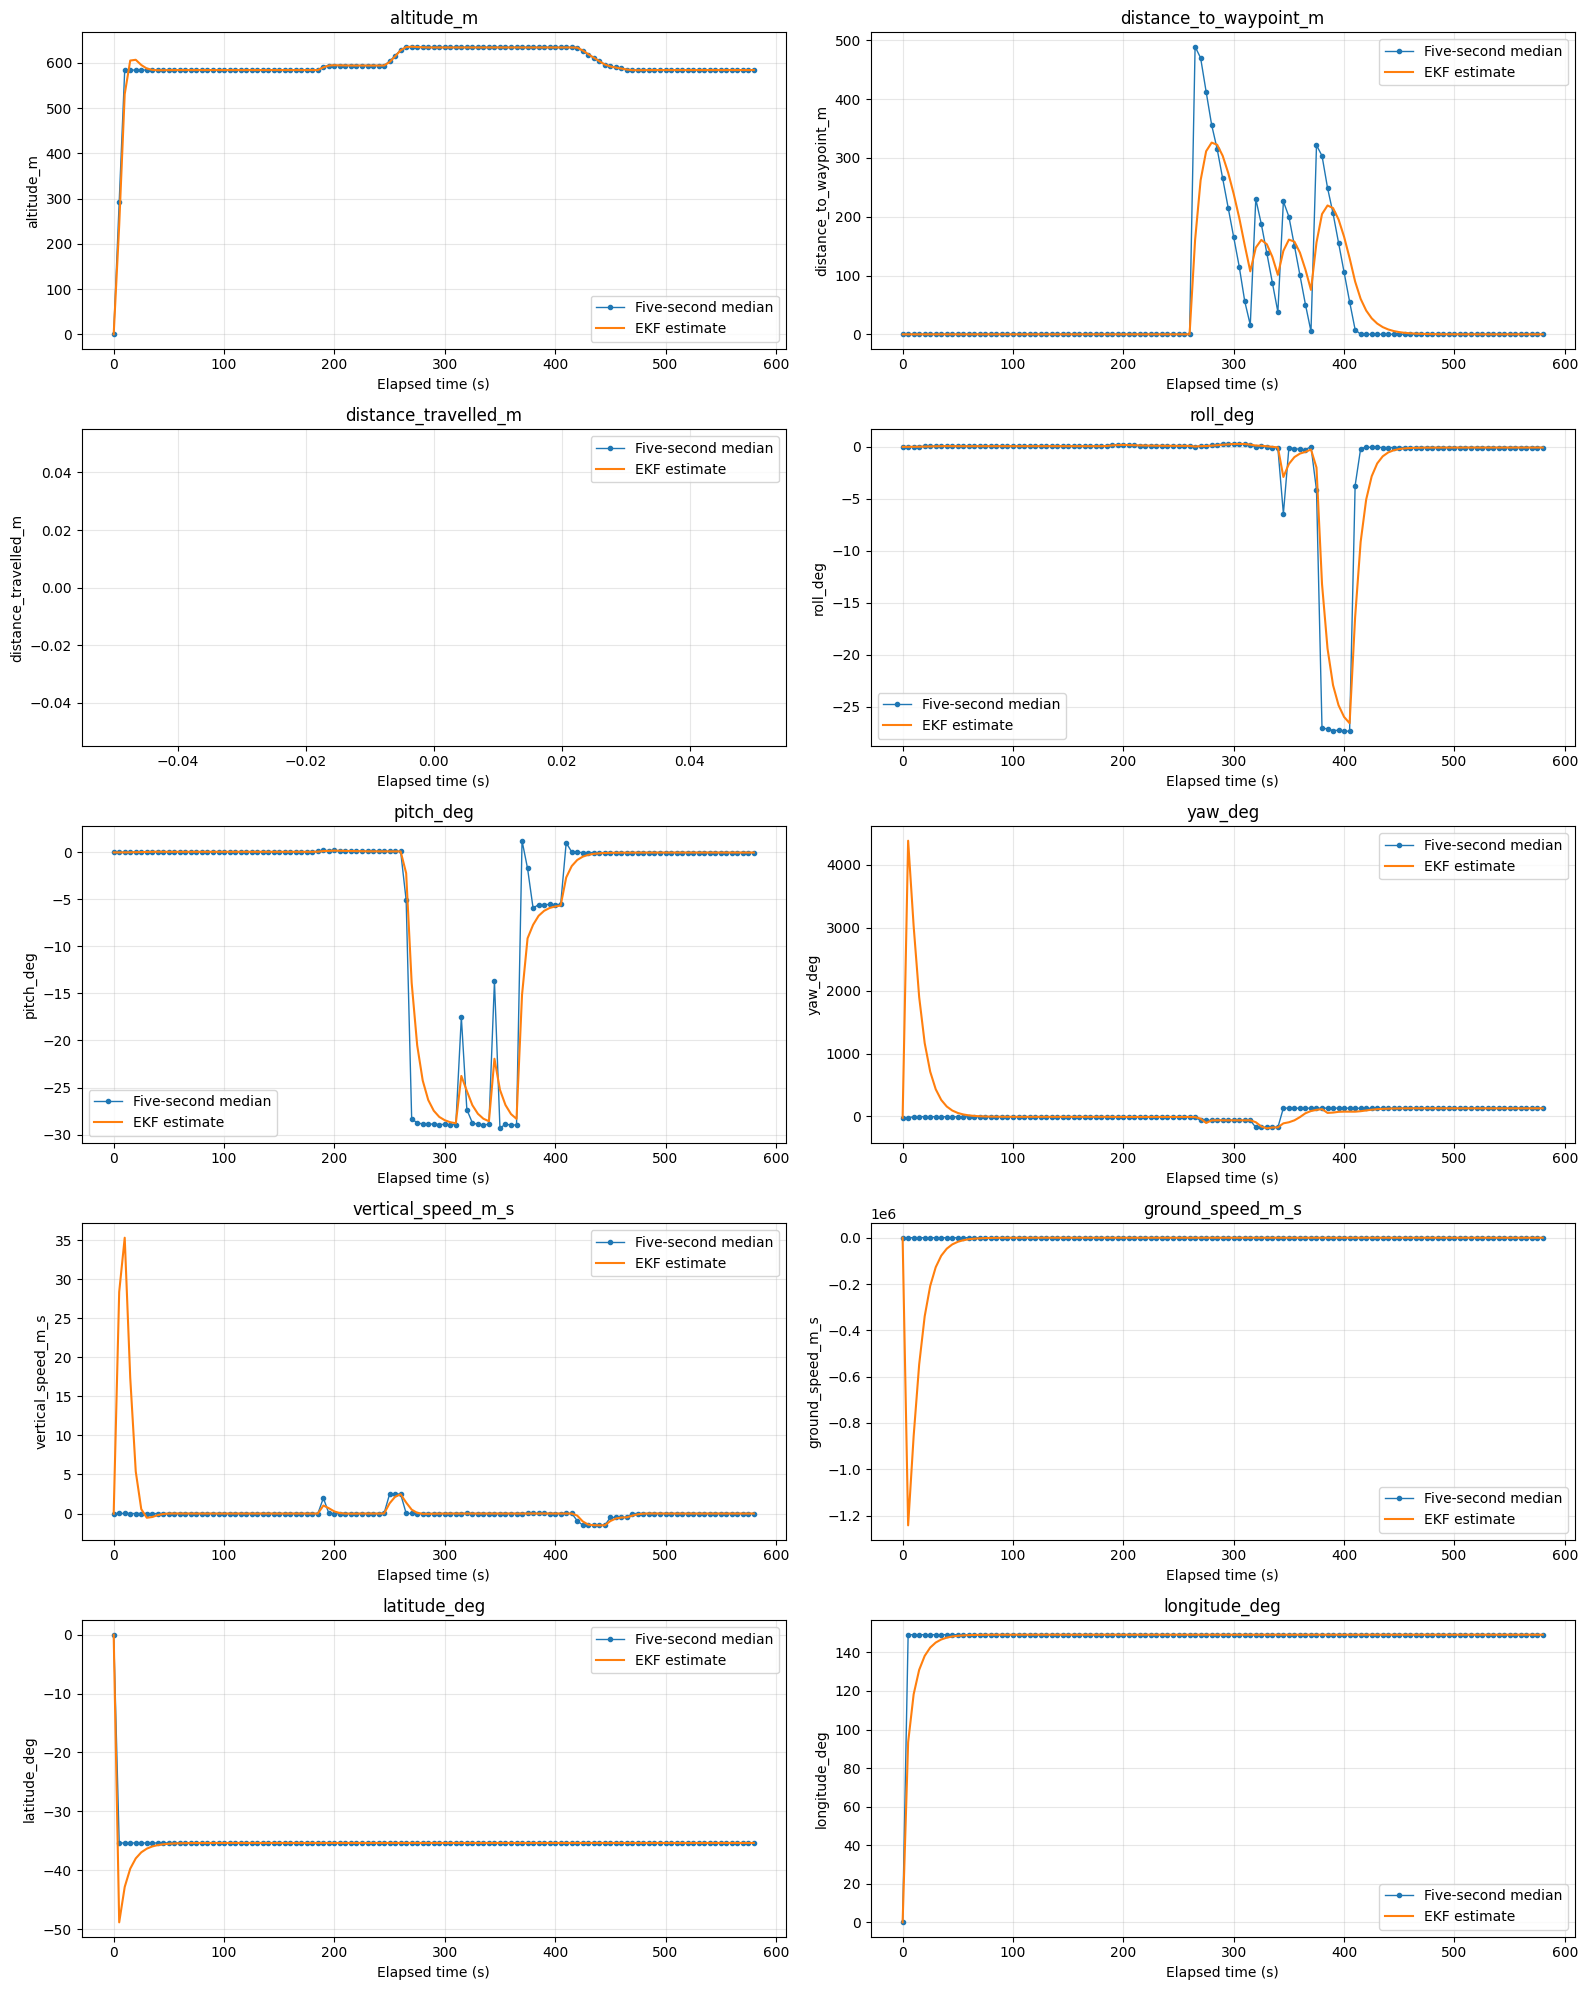

In [37]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for i, feature in enumerate(FEATURES):
    ax = axes[i]

    ax.plot(
        median_ekf_data["time_s"],
        median_ekf_data[feature],
        marker="o",
        markersize=3,
        linewidth=1,
        label="Five-second median",
    )

    ax.plot(
        median_ekf_data["time_s"],
        median_ekf_data[f"{feature}_ekf"],
        linewidth=1.5,
        label="EKF estimate",
    )

    ax.set_title(feature)
    ax.set_xlabel("Elapsed time (s)")
    ax.set_ylabel(feature)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# 12. Check bins with no measurements

In [38]:
empty_bins = median_ekf_data[
    median_ekf_data["no_measurements_in_bin"]
]

print("Bins with no available feature measurements:", len(empty_bins))
display(empty_bins[["time_s", "no_measurements_in_bin", "timestamp_gap"]])

Bins with no available feature measurements: 0


,time_s,no_measurements_in_bin,timestamp_gap
